<a href="https://colab.research.google.com/github/alkadevirajbanshi-ai/BIg_data/blob/main/CN7031_Week5_Extra_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CN7031 · Week 5 Extra Lab — Working with Unstructured Data in Hadoop

---

**Practical lab workbook | Big Data Analytics (CN7031) 2026-27**
**Dr Fahimeh Jafari** : [F.Jafari@uel.ac.uk](mailto:F.Jafari@uel.ac.uk)

---

This is an **optional** lab for those who want to go further after the main Week 5 lab on Spark DataFrames and Spark SQL.

### Learning outcomes
After completing this lab, you should:
- be able to work with **unstructured data** in Hadoop;
- be able to create **tables in Hive** that allow structured querying of unstructured data;
- know some advanced Hive techniques for unstructured data: **SerDes**, external tables and two-step loading;
- understand how **Impala** gives fast, interactive SQL on these tables, and use **Spark SQL** for the same job.

### Unstructured data
 In the main lab the data came as a CSV file with a header: it was already **structured** into columns. Much real data is not. A web server writes one line of free text for every request, for example:

```
48.138.27.161 - - [31/Mar/2015:21:53:15 -0400] "GET /home HTTP/1.1" 200 570 "-" "Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/35.0.1916.153 Safari/537.36"
```

| Part of the line | Meaning |
| :-- | :-- |
| `48.138.27.161` | IP address of the visitor |
| `- -` | Identity and user name (not recorded, so `-`) |
| `[31/Mar/2015:21:53:15 -0400]` | Date and time of the request, with the time-zone offset |
| `"GET /home HTTP/1.1"` | Method, page (URL) and protocol version |
| `200` | Status code: 200 OK, 304 not modified, 404 not found, 500 server error |
| `570` | Size of the response in bytes |
| `"-"` | The page the visitor came from (the *referrer*) |
| `"Mozilla/5.0 …"` | The visitor's browser and operating system (the *user agent*) |

There are no commas or tabs to split on: spaces appear inside the date, the request and the user agent. In this lab you store the log in **HDFS**, describe it to **Hive** with a regular expression, copy it into a clean table, and analyse it with SQL.

| Phase | What happens | Tools |
| :-- | :-- | :-- |
| 1. Bulk upload (Steps 1–2) | Copy the log into HDFS | `hdfs dfs` |
| 2. Create tables (Step 3) | An intermediate table that parses the log with a **RegexSerDe**, then a final table | Hive statements, run by Spark SQL with Hive support |
| 3. Analyse (Steps 4–5) | Refresh the metadata, then answer four questions | Impala on Cloudera; **Spark SQL** here |

### The data
 The original lab uses a web server access log of 5 million requests (about 1 GB). You can download it [here](https://uelac-my.sharepoint.com/:f:/g/personal/karami_uel_ac_uk/EjZUG5siKeRLjbsLUa1BBY4B7DohlkY4egVvMZyiPshf_w?e=QcPOz8) (a UEL OneDrive login is needed).

A 1 GB file takes a long time to upload to Colab, so Step 1.2 can make a **sample instead**: a **synthetic** log of 300,000 requests to an imaginary sports shop, in exactly the same format. It is generated with a fixed random seed, so everyone gets the same file and the same results as the Expected lines.

- **To use the real log:** download `access.log` from the link above, upload it to `/content` (Colab's **Files** pane) **before** running 1.2, and 1.2 uses it instead of making the sample. Your results will then differ from the Expected lines, and each step takes longer.
- **To use the sample:** just run 1.2.

### How to use the notebook
- Use **Google Colab → Python 3 → CPU**. Run the cells in order, starting from Section 1. On a fresh runtime, Section 1 takes about 5 minutes.
- The code cells are **Python**; a line starting with `!` runs a terminal command, such as `hdfs dfs`. Each cell starts with a comment line (`#`) that says what it does.
- Cells with a **▶ title** and hidden code prepare the lab: run them, but you do not need to read their code.

**Important:** Colab storage is temporary and is deleted when its runtime resets. If that happens, run Section 1 again.

## 1. Getting ready

**Goal:** Install Spark, start HDFS, and prepare the data.

### 1.1 Install Java and Spark

**Goal:** Spark runs on the Java Virtual Machine, so it needs Java. **PySpark** is the Python package that contains Spark itself. This cell installs Java 17 and PySpark 4.0.4.

**Expected output:** a line starting `openjdk version "17…`, then `PySpark 4.0.4 is installed ✓  Java 17 is ready ✓`.

In [1]:
# @title ▶ 1.1 Install Java 17 and Apache Spark (PySpark 4.0.4)
# Import the tools used to run installation commands and check the result.
import os
import subprocess
import sys
from pathlib import Path

# Spark runs on the Java Virtual Machine; Spark 4 needs Java 17 or newer.
SPARK_VERSION = '4.0.4'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=900):
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, timeout=timeout)
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    return p.stdout

# Install Java 17 only when it is not already on this VM.
if not (JAVA / 'bin/java').exists():
    print('Installing Java 17 …')
    checked(['apt-get', 'update', '-qq'])
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Point Spark at Java 17.
os.environ['JAVA_HOME'] = str(JAVA)
os.environ['PATH'] = f'{JAVA}/bin:' + os.environ['PATH']

# Install the PySpark package (Spark itself is bundled inside it), only if this version is missing.
from importlib.metadata import version, PackageNotFoundError
try:
    installed = version('pyspark')
except PackageNotFoundError:
    installed = None
if installed != SPARK_VERSION:
    print(f'Installing PySpark {SPARK_VERSION} (about 450 MB) …')
    checked([sys.executable, '-m', 'pip', 'install', '-q', f'pyspark=={SPARK_VERSION}'])
    if 'pyspark' in sys.modules:
        print('An older PySpark was already loaded: choose Runtime → Restart session, then run this cell again.')

# Spark's own log messages (INFO and WARN) would fill the cell outputs: show only errors.
SPARK_CONF = Path('/content/spark-conf')
SPARK_CONF.mkdir(parents=True, exist_ok=True)
(SPARK_CONF / 'log4j2.properties').write_text(
    'rootLogger.level = error\n'
    'rootLogger.appenderRef.stdout.ref = console\n'
    'appender.console.type = Console\n'
    'appender.console.name = console\n'
    'appender.console.target = SYSTEM_ERR\n'
    'appender.console.layout.type = PatternLayout\n'
    'appender.console.layout.pattern = %p %c{1}: %m%n\n'
    'logger.repl.name = org.apache.spark.repl.Main\n'
    'logger.repl.level = error\n')
os.environ['SPARK_CONF_DIR'] = str(SPARK_CONF)

# Java's start-up notices go to a log file instead of the notebook (Spark errors still appear in Python).
import pyspark.java_gateway as java_gateway
if not getattr(java_gateway.Popen, 'quiet', False):
    start_java = java_gateway.Popen
    def quiet_popen(command, **kwargs):
        kwargs.setdefault('stderr', open(SPARK_CONF / 'java.log', 'ab'))
        return start_java(command, **kwargs)
    quiet_popen.quiet = True
    java_gateway.Popen = quiet_popen

# When a query has a mistake, show only Python's short error message, not an extra JSON log of it.
from pyspark.logger import PySparkLogger
for name in ('SQLQueryContextLogger', 'DataFrameQueryContextLogger'):
    PySparkLogger.getLogger(name).disabled = True

# Show what was installed.
java_version = checked([str(JAVA / 'bin/java'), '-version']).splitlines()[0]
print(java_version)
print(f'PySpark {SPARK_VERSION} is installed ✓  Java 17 is ready ✓')

Installing Java 17 …
openjdk version "17.0.20.1" 2026-08-18
PySpark 4.0.4 is installed ✓  Java 17 is ready ✓


### 1.2 Start HDFS and prepare the files

**Goal:** Start a one-machine **HDFS** (one NameNode and one DataNode, as in Weeks 2–4), place the access log on Colab's local disk as `/content/access.log` (like the copy on the VM's Desktop), and download **hive-contrib**, the Hive library used in Step 3. The first run downloads Hadoop and takes 3–5 minutes.

**Expected:** `HDFS is ready ✓`, then `Sample log created: /content/access.log, 300,000 lines, 62.5 MB ✓`, then `/content/hive-contrib.jar is ready ✓`.

In [2]:
# @title ▶ 1.2 Start HDFS, create the sample access log and download hive-contrib
# This lab needs a SparkSession with Hive support (Step 3): stop any other SparkSession still running in this runtime.
from pyspark.sql import SparkSession
active = SparkSession.getActiveSession()
if active is not None and active.conf.get('spark.sql.catalogImplementation') != 'hive':
    active.stop()

# Import paths, operating-system utilities, download and checksum tools.
from pathlib import Path
import os
import subprocess
import urllib.request
import urllib.error
import hashlib
import re
import tarfile
import time

# Import XML tools to create Hadoop and Hive configuration files.
from xml.etree import ElementTree as ET

# Import the HTTP client used to check the NameNode and DataNode web services.
import requests

# Set a persistent path within the current temporary Colab runtime.
LAB = Path('/content/cn7031-week5-hdfs')
# Create the working directory when it does not exist.
LAB.mkdir(parents=True, exist_ok=True)
# Specify the Hadoop and Java paths.
HADOOP = LAB / 'hadoop-3.5.0'
JAVA = Path('/usr/lib/jvm/java-17-openjdk-amd64')

# Run a system command and stop with a useful error if it fails.
def checked(args, timeout=600, env=None, cwd=None):
    # Capture standard output and errors as readable text.
    p = subprocess.run(args, text=True, stdout=subprocess.PIPE,
                       stderr=subprocess.STDOUT, timeout=timeout, env=env, cwd=cwd)
    # Check the exit status before using the command's result.
    if p.returncode:
        raise RuntimeError(p.stdout[-5000:])
    # Return the printed output to the caller.
    return p.stdout

# Match a digest's length (in hexadecimal characters) to the algorithm that produced it.
DIGEST_BY_LENGTH = {32: 'md5', 40: 'sha1', 64: 'sha256', 128: 'sha512'}

# Read the first checksum file a publisher provides next to a download.
def published_digest(url, suffixes):
    # Remember the filename so it can be removed from the checksum text.
    name = url.rsplit('/', 1)[-1]
    for suffix in suffixes:
        try:
            # Download the small checksum file, e.g. file.tar.gz.sha512.
            with urllib.request.urlopen(url + suffix, timeout=60) as response:
                text = response.read().decode(errors='replace')
        except (urllib.error.URLError, TimeoutError):
            # Try the next checksum format if this one is not published.
            continue
        # Remove the filename, then keep only the hexadecimal groups.
        tokens = re.split(r'[\s:=()*]+', text.replace(name, ' '))
        digest = ''.join(t for t in tokens if re.fullmatch(r'[0-9a-fA-F]+', t)).lower()
        # Return the algorithm and digest when the length is recognised.
        if len(digest) in DIGEST_BY_LENGTH:
            return DIGEST_BY_LENGTH[len(digest)], digest
    # No usable checksum file was found.
    return None, None

# Download a file, showing progress, and keep it only if it matches the published checksum.
def download_verified(url, dest, suffixes, required=True, checksum_url=None):
    # Download into a temporary name so a failed check leaves nothing behind.
    partial = dest.with_name(dest.name + '.part')
    # timeout=60: a connection that stalls for a minute raises an error instead of hanging forever.
    with urllib.request.urlopen(url, timeout=60) as response, partial.open('wb') as out:
        total = int(response.headers.get('Content-Length') or 0)
        done, step = 0, -1
        while chunk := response.read(1 << 20):
            out.write(chunk)
            done += len(chunk)
            # Report progress in 10% steps for large downloads only.
            if total > 50_000_000 and done * 10 // total > step:
                step = done * 10 // total
                print(f'  Download: {step * 10}%  ({done >> 20} of {total >> 20} MB)')
    # Look up the publisher's checksum for this exact file (a few attempts: the file is tiny but sites can be slow).
    for attempt in range(3):
        algorithm, expected = published_digest(checksum_url or url, suffixes)
        if algorithm:
            break
        time.sleep(3)
    if algorithm is None:
        # Stop, unless this download is allowed to proceed without a checksum.
        if required:
            partial.unlink()
            raise RuntimeError(f'No checksum published for {url}.')
        print(f'  Note: no checksum file found for {dest.name}; continuing without one.')
    else:
        # Calculate the digest of the downloaded file with the same algorithm.
        with partial.open('rb') as stream:
            actual = hashlib.file_digest(stream, algorithm).hexdigest()
        # Reject the file if the digests do not match.
        if actual != expected:
            partial.unlink()
            raise RuntimeError(f'Download checksum failed for {dest.name}.')
        print(f'  {algorithm.upper()} checksum verified: {dest.name}')
    # Give the verified file its final name.
    partial.replace(dest)

# Where to download Apache releases from, fastest first. The CDN and main site carry only the newest
# releases; a public mirror keeps older ones; the Apache archive keeps every release but can be slow.
APACHE_SITES = ('https://dlcdn.apache.org', 'https://downloads.apache.org',
                'https://repo.huaweicloud.com/apache', 'https://archive.apache.org/dist')
APACHE_ARCHIVE = 'https://archive.apache.org/dist'

# Download an Apache release, trying each site in turn (twice each) until one works.
def download_apache(path, dest, suffixes, required=True):
    problems = []
    for site in APACHE_SITES:
        for attempt in (1, 2):
            try:
                print(f'  Trying {site} …')
                # Checksums always come from Apache itself, even when the file comes from a mirror.
                official = site if 'apache.org' in site else APACHE_ARCHIVE
                download_verified(f'{site}/{path}', dest, suffixes, required, f'{official}/{path}')
                return
            except urllib.error.HTTPError as error:
                # Not on this site (e.g. 404 after a release moves to the archive): try the next site.
                problems.append(f'{site}: HTTP {error.code}')
                break
            except (OSError, RuntimeError) as error:
                # Timeout, dropped connection or bad checksum: wait, then retry.
                problems.append(f'{site}: {error}')
                print(f'  Problem: {error}. Retrying …')
                time.sleep(5)
    raise RuntimeError('Could not download ' + path + ' from any Apache site:\n' + '\n'.join(problems))

# Install Java 17 only when it is not already available.
if not (JAVA / 'bin/java').exists():
    # Update package metadata for the Colab VM.
    print('Installing Java …')
    checked(['apt-get', 'update', '-qq'])
    # Install the headless JDK required by Hadoop, Hive and Pig.
    checked(['apt-get', 'install', '-y', '-qq', 'openjdk-17-jdk-headless'])

# Download, verify and unpack Hadoop only once per current VM.
if not (HADOOP / '.verified').exists():
    print('Downloading Hadoop from Apache (about 554 MB) …')
    archive = LAB / 'hadoop-3.5.0.tar.gz'
    download_apache('hadoop/common/hadoop-3.5.0/hadoop-3.5.0.tar.gz', archive, ('.sha512',))
    # Extract the verified archive safely.
    print('Installing Hadoop …')
    with tarfile.open(archive) as bundle:
        bundle.extractall(LAB, filter='data')
    # Record successful installation and remove the compressed archive.
    (HADOOP / '.verified').write_text('ok')
    archive.unlink()

# Set Java and Hadoop environment variables for child processes (!, %%bash, hive, pig).
os.environ.update(JAVA_HOME=str(JAVA), HADOOP_HOME=str(HADOOP),
                  HADOOP_CONF_DIR=str(HADOOP / 'etc/hadoop'),
                  HADOOP_LOG_DIR=str(LAB / 'logs'), HADOOP_PID_DIR=str(LAB / 'pids'),
                  HADOOP_COMMON_HOME=str(HADOOP), HADOOP_MAPRED_HOME=str(HADOOP))
# Open the JDK internals that Hadoop, Hive and Pig still use on Java 17.
OPENS = ' '.join(f'--add-opens={m}=ALL-UNNAMED' for m in (
    'java.base/java.lang', 'java.base/java.lang.invoke', 'java.base/java.lang.reflect',
    'java.base/java.io', 'java.base/java.net', 'java.base/java.nio', 'java.base/java.util',
    'java.base/java.util.concurrent', 'java.base/java.util.concurrent.atomic',
    'java.base/java.util.regex', 'java.base/java.text', 'java.base/sun.nio.ch',
    'java.base/sun.nio.cs', 'java.base/sun.security.action', 'java.base/sun.util.calendar',
    'java.sql/java.sql'))
os.environ['HADOOP_CLIENT_OPTS'] = f'-Xmx1g {OPENS}'
# Put Hadoop and Java executables on the shell PATH.
os.environ['PATH'] = f'{HADOOP}/bin:{JAVA}/bin:' + os.environ['PATH']
# Make separate folders for namespace metadata, blocks, logs and process IDs.
for name in ('namenode', 'datanode', 'logs', 'pids'):
    (LAB / name).mkdir(exist_ok=True)

# Write a Hadoop-style XML configuration file (Hadoop's config folder unless another is given).
def config(name, values, folder=None):
    # Create the configuration root element.
    root = ET.Element('configuration')
    # Add each property name and its value.
    for key, value in values.items():
        property_node = ET.SubElement(root, 'property')
        ET.SubElement(property_node, 'name').text = key
        ET.SubElement(property_node, 'value').text = str(value)
    # Save the resulting configuration file.
    ET.ElementTree(root).write(Path(folder or HADOOP / 'etc/hadoop') / name, encoding='utf-8')

# Point HDFS clients at the local NameNode using port 9000.
config('core-site.xml', {
    'fs.defaultFS': 'hdfs://127.0.0.1:9000',
    'hadoop.tmp.dir': str(LAB / 'tmp'),
})
# Assign local storage directories and a default replication factor of one.
config('hdfs-site.xml', {
    'dfs.namenode.name.dir': (LAB / 'namenode').as_uri(),
    'dfs.datanode.data.dir': (LAB / 'datanode').as_uri(),
    'dfs.replication': 1,
    # Bind RPC and health-report endpoints to the VM's loopback address.
    'dfs.namenode.rpc-address': '127.0.0.1:9000',
    'dfs.namenode.rpc-bind-host': '127.0.0.1',
    'dfs.namenode.http-address': '127.0.0.1:9870',
    'dfs.namenode.http-bind-host': '127.0.0.1',
    # Keep DataNode transfer, HTTP and IPC endpoints on localhost.
    'dfs.datanode.address': '127.0.0.1:9866',
    'dfs.datanode.http.address': '127.0.0.1:9864',
    'dfs.datanode.ipc.address': '127.0.0.1:9867',
    'dfs.datanode.hostname': '127.0.0.1',
    'dfs.client.use.datanode.hostname': 'true',
    'dfs.datanode.use.datanode.hostname': 'true',
})
# Run Hive's MapReduce jobs in local mode (inside the HiveServer2 process, no YARN cluster).
config('mapred-site.xml', {
    'mapreduce.framework.name': 'local',
    # Keep each job's temporary staging files in one HDFS folder.
    'mapreduce.jobtracker.staging.root.dir': '/tmp/hadoop-staging',
})

# Add Java and a default heap size to Hadoop's environment script once.
# The heap can still be raised per process (HiveServer2 gets more in Step 1.2).
env = HADOOP / 'etc/hadoop/hadoop-env.sh'
if 'CN7031 environment' not in env.read_text():
    env.write_text(env.read_text() + f'\n# CN7031 environment\nexport JAVA_HOME={JAVA}\n'
                   'export HADOOP_HEAPSIZE_MAX=${HADOOP_HEAPSIZE_MAX:-512}\n')

# Show only warnings and errors from Hadoop's internals, so commands print short output.
log4j = HADOOP / 'etc/hadoop/log4j.properties'
QUIET = ['log4j.logger.org.apache.hadoop=WARN',
         'log4j.logger.org.apache.hadoop.fs.FileUtil=ERROR',
         'log4j.logger.org.apache.hadoop.mapred.LocalDistributedCacheManager=ERROR',
         'log4j.logger.org.apache.hadoop.metrics2.impl.MetricsSystemImpl=ERROR']
if log4j.exists():
    text = log4j.read_text()
    missing = [line for line in QUIET if line not in text]
    if missing:
        log4j.write_text(text + '\n# CN7031: quieter client output\n' + '\n'.join(missing) + '\n')

# Format only when no NameNode filesystem already exists.
if not (LAB / 'namenode/current/VERSION').exists():
    # Never silently overwrite an unexpectedly populated storage directory.
    assert all(not any((LAB / name).iterdir()) for name in ('namenode', 'datanode')), \
        'Existing storage found. Do not reformat it.'
    # Give the new HDFS namespace a fixed educational cluster ID.
    checked(['hdfs', 'namenode', '-format', '-nonInteractive', '-clusterid', 'CID-cn7031-week5'])

# Start a service only if its local HTTP endpoint is not responding.
for daemon, port in [('namenode', 9870), ('datanode', 9864)]:
    try:
        # Raise an error on a missing or unhealthy service endpoint.
        requests.get(f'http://127.0.0.1:{port}/jmx', timeout=2).raise_for_status()
    except requests.RequestException:
        # Start the selected Hadoop daemon in the background.
        checked(['hdfs', '--daemon', 'start', daemon])

# Wait until the NameNode reports exactly one live DataNode.
for attempt in range(45):
    try:
        # Query NameNode's JMX metrics over its local HTTP endpoint.
        response = requests.get('http://127.0.0.1:9870/jmx',
                                params={'qry': 'Hadoop:service=NameNode,name=FSNamesystemState'},
                                timeout=3)
        response.raise_for_status()
        # Exit the retry loop when the teaching cluster is ready.
        if response.json()['beans'][0]['NumLiveDataNodes'] == 1:
            break
    except (requests.RequestException, KeyError, IndexError):
        # Retry while the services finish their startup sequence.
        pass
    # Pause two seconds before asking again.
    time.sleep(2)
else:
    # Stop if the DataNode never becomes available.
    raise RuntimeError(f'Startup failed. Inspect the Hadoop logs in {LAB / "logs"}.')

# Wait until the NameNode has left safe mode, allowing writes.
checked(['hdfs', 'dfsadmin', '-safemode', 'wait'], timeout=90)
print('HDFS is ready ✓  Hadoop 3.5.0 · NameNode running · 1 DataNode running')

import random
from datetime import datetime, timedelta

# The access log on Colab's local disk, like the downloaded copy on the VM's Desktop.
# If you uploaded the full access.log to /content, it is used instead of the sample.
LOG = Path('/content/access.log')
if LOG.exists():
    print(f'Using the access.log in /content ({LOG.stat().st_size / 1e6:.0f} MB).')
else:
    print('Creating a sample access log (300,000 requests) …')
    rnd = random.Random(2015)
    departments = {'apparel': ['mens-tshirts', 'womens-jackets', 'kids-shoes'],
                   'fitness': ['cardio-equipment', 'strength-training', 'yoga'],
                   'footwear': ['running-shoes', 'boots', 'sandals'],
                   'golf': ['golf-balls', 'golf-clubs', 'golf-bags'],
                   'outdoors': ['tents', 'camping-hiking', 'fishing'],
                   'fan shop': ['team-shirts', 'hats', 'souvenirs']}
    products = [f'/product/{name}-{n}' for name in ('nike-air-max', 'perfect-fitness-rip-deck', 'under-armour-jacket',
                'o-brien-life-vest', 'field-and-stream-safe', 'pelican-kayak', 'diamondback-bike', 'adidas-ball',
                'garmin-watch', 'coleman-tent') for n in range(1, 21)]
    pages = (['/home'] * 30 + ['/login'] * 6 + ['/checkout'] * 4 + ['/support'] * 2 + ['/search'] * 5
             + [f'/department/{d.replace(" ", "%20")}' for d in departments] * 3
             + [f'/department/{d.replace(" ", "%20")}/category/{c}' for d, cs in departments.items() for c in cs]
             + products[:40] * 2 + products)
    agents = ['Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/35.0.1916.153 Safari/537.36'] * 9 \
        + ['Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/36.0.1985.125 Safari/537.36'] * 5 \
        + ['Mozilla/5.0 (Windows NT 6.1; WOW64; rv:30.0) Gecko/20100101 Firefox/30.0'] * 4 \
        + ['Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_2 like Mac OS X) AppleWebKit/537.51.2 (KHTML, like Gecko) Version/7.0 Mobile/11D257 Safari/9537.53'] * 3 \
        + ['Mozilla/5.0 (compatible; MSIE 10.0; Windows NT 6.1; Trident/6.0)'] * 2 \
        + ['Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html)']
    visitors = [f'{rnd.randint(1, 223)}.{rnd.randint(0, 255)}.{rnd.randint(0, 255)}.{rnd.randint(1, 254)}'
                for _ in range(25000)]
    crawlers = [f'66.249.{rnd.randint(64, 95)}.{rnd.randint(1, 254)}' for _ in range(12)]
    # Busier in the evening than at night: a weight for each hour of the day.
    hour_weight = [2, 1, 1, 1, 1, 2, 3, 5, 7, 8, 9, 9, 10, 10, 9, 9, 10, 11, 13, 15, 16, 14, 9, 5]
    start = datetime(2015, 3, 25)
    with LOG.open('w') as out:
        for _ in range(300000):
            if rnd.random() < 0.02:
                ip, page, agent = rnd.choice(crawlers), rnd.choice(products), agents[-1]
            else:
                ip, page, agent = rnd.choice(visitors), rnd.choice(pages), rnd.choice(agents[:-1])
            when = start + timedelta(days=rnd.randrange(7), hours=rnd.choices(range(24), hour_weight)[0],
                                     minutes=rnd.randrange(60), seconds=rnd.randrange(60))
            method = 'POST' if page in ('/login', '/checkout') and rnd.random() < 0.6 else 'GET'
            status = rnd.choices([200, 304, 404, 500], [90, 5, 4, 1])[0]
            size = rnd.randint(300, 9000) if status == 200 else rnd.randint(0, 600)
            out.write(f'{ip} - - [{when:%d/%b/%Y:%H:%M:%S} -0400] "{method} {page} HTTP/1.1" '
                      f'{status} {size} "-" "{agent}"\n')

    lines = sum(1 for _ in LOG.open())
    print(f'Sample log created: {LOG}, {lines:,} lines, {LOG.stat().st_size / 1e6:.1f} MB ✓')

# hive-contrib: the Hive library with the contributed RegexSerDe used in this lab, from Maven Central.
CONTRIB = Path('/content/hive-contrib.jar')
if not CONTRIB.exists():
    download_verified('https://repo1.maven.org/maven2/org/apache/hive/hive-contrib/2.3.10/hive-contrib-2.3.10.jar',
                      CONTRIB, ('.sha1',))
print(f'{CONTRIB} is ready ✓')

  Trying https://dlcdn.apache.org …
  Download: 0%  (1 of 554 MB)
  Download: 10%  (56 of 554 MB)
  Download: 20%  (111 of 554 MB)
  Download: 30%  (167 of 554 MB)
  Download: 40%  (222 of 554 MB)
  Download: 50%  (278 of 554 MB)
  Download: 60%  (333 of 554 MB)
  Download: 70%  (389 of 554 MB)
  Download: 80%  (444 of 554 MB)
  Download: 90%  (499 of 554 MB)
  Download: 100%  (554 of 554 MB)
  SHA512 checksum verified: hadoop-3.5.0.tar.gz
Installing Hadoop …
HDFS is ready ✓  Hadoop 3.5.0 · NameNode running · 1 DataNode running
Creating a sample access log (300,000 requests) …
Sample log created: /content/access.log, 300,000 lines, 62.5 MB ✓
  SHA1 checksum verified: hive-contrib.jar
/content/hive-contrib.jar is ready ✓


## 2. Phase 1: Bulk upload data

### Step 1: Copy the data to HDFS

**Goal:** Move the log from the local disk into HDFS, into the folder the Hive table will read.

| Command | Meaning |
| :-- | :-- |
| `hdfs dfs -mkdir -p /user/hive/warehouse/access_log` | Create the folder, with any missing parent folders (`-p`) |
| `hdfs dfs -put -f /content/access.log /user/hive/warehouse/access_log` | Copy the local file into it; `-f` overwrites a copy that is already there |
| `hdfs dfs -chmod -R 777 /user/hive/warehouse/access_log` | Give everyone read, write and execute permission (`777`) on the folder and everything in it (`-R`), so Hive, Impala and other users can read it |

These commands print nothing when they succeed.

In [3]:
# Create the HDFS folder, copy the log into it, and open its permissions.
!hdfs dfs -mkdir -p /user/hive/warehouse/access_log
!hdfs dfs -put -f /content/access.log /user/hive/warehouse/access_log
!hdfs dfs -chmod -R 777 /user/hive/warehouse/access_log

### Step 2: Verify the data is in HDFS, and delete the original from the local disk

**Goal:** Check that the file arrived, then delete the local copy: in a real system you would not keep a second 1 GB copy of the data outside HDFS.

**Expected:** one file, `access.log`, of about 62 MB, with permissions `-rwxrwxrwx`; then three request lines.

`head -n 3` stops reading after three lines, and `hdfs dfs -cat` would then complain that it cannot write the rest. `2>/dev/null` hides that harmless message: `2>` redirects the error output, and `/dev/null` discards it.

In [4]:
# List the HDFS folder: the log is there, with open permissions.
!hdfs dfs -ls /user/hive/warehouse/access_log

Found 1 items
-rwxrwxrwx   1 root supergroup   62503798 2026-10-30 16:30 /user/hive/warehouse/access_log/access.log


In [5]:
# Show the first three lines of the log, read from HDFS.
!hdfs dfs -cat /user/hive/warehouse/access_log/access.log 2>/dev/null | head -n 3

87.73.228.43 - - [26/Mar/2015:20:04:07 -0400] "GET /product/under-armour-jacket-9 HTTP/1.1" 200 5766 "-" "Mozilla/5.0 (Windows NT 6.1; WOW64; rv:30.0) Gecko/20100101 Firefox/30.0"
219.249.37.73 - - [28/Mar/2015:10:50:20 -0400] "GET /product/adidas-ball-4 HTTP/1.1" 200 7605 "-" "Mozilla/5.0 (compatible; MSIE 10.0; Windows NT 6.1; Trident/6.0)"
91.167.38.241 - - [27/Mar/2015:20:59:35 -0400] "GET /home HTTP/1.1" 200 7431 "-" "Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_2 like Mac OS X) AppleWebKit/537.51.2 (KHTML, like Gecko) Version/7.0 Mobile/11D257 Safari/9537.53"


In [6]:
# Delete the original file from the local disk; the data now lives in HDFS.
!rm -f /content/access.log

## 3. Phase 2: Create tables in Hive

### Step 3: Create a table in Hive

On Cloudera you would create the tables in **Hive** (Hue's Hive editor), then query them with **Impala** and **Hue**. Table creation has two steps. First, you use a **Hive SerDe** to parse the logs into separate fields with a regular expression. Then you copy the data from this intermediate table into a final table that does not need any special SerDe. Once the data is in the final table, it can be queried faster and more interactively.

**What is a Hive SerDe?** SerDe stands for **Serializer/Deserializer**. It is the part of Hive that sits between the bytes stored in HDFS and the table definitions in the metastore: it lets Hive interpret the data as a table. Hive reads and writes formats such as CSV, JSON, Avro, ORC and Parquet through SerDes. Hive's SerDe library contains built-in SerDes, and you can write your own for a custom format. The SerDe tells Hive how to process each record (row): how to **deserialise** it (bytes → columns) when reading, and how to **serialise** it (columns → bytes) when writing. This gives the data a structure that can be queried efficiently. The file itself never changes: as in Week 4, this is **schema-on-read**.

In this notebook, **Spark SQL with Hive support** runs the Hive statements: Spark uses Hive's metastore, Hive's table definitions and Hive's SerDes, so the statements are the same as in the Hive editor.

#### Start Spark with Hive support

| Setting | Meaning |
| :-- | :-- |
| `.enableHiveSupport()` | Use a **Hive metastore** and allow Hive SerDes and Hive table definitions |
| `spark.hadoop.fs.defaultFS` | Paths without a prefix, such as `/user/hive/warehouse/access_log`, refer to **HDFS** on this machine |
| `spark.sql.warehouse.dir` | Hive's warehouse folder in HDFS, as on Cloudera |

**Expected:** `Catalog: hive`.

In [7]:
# Start a SparkSession with Hive support, reading and writing HDFS.
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Working with unstructured data") \
    .master("local[*]") \
    .config("spark.hadoop.fs.defaultFS", "hdfs://127.0.0.1:9000") \
    .config("spark.sql.warehouse.dir", "/user/hive/warehouse") \
    .enableHiveSupport() \
    .getOrCreate()

print("Catalog:", spark.conf.get("spark.sql.catalogImplementation"))

Catalog: hive


#### Add hive-contrib.jar

`hive-contrib.jar` is a Java library (JAR file) with additional, **contributed** functionality for Apache Hive: extensions, utilities and features that are not part of the core Hive distribution. They are developed and maintained by the Hive community, and include extra **UDFs** (user-defined functions), **SerDes**, input/output formats and other utilities that extend what Hive can do. This lab uses its **RegexSerDe**.

`ADD JAR` loads a JAR into the current session. On Cloudera the file was at `/usr/lib/hive/lib/hive-contrib.jar`, and the lab added it just before the `INSERT` in step d); Spark needs it before the table is first used, so add it now. `LIST JARS` shows the JARs the session has loaded.

**Expected:** a line ending in `hive-contrib.jar`.

In [8]:
# Add the hive-contrib library to the session, and list the added JARs.
spark.sql("ADD JAR /content/hive-contrib.jar")
spark.sql("LIST JARS").show(truncate=False)

+------------------------------------------------+
|Results                                         |
+------------------------------------------------+
|spark://edf69a238daf:35537/jars/hive-contrib.jar|
+------------------------------------------------+



#### a) Drop an existing table, and b) create an intermediate table

`DROP TABLE IF EXISTS` removes an earlier version, so the cell can be run again. Then `CREATE EXTERNAL TABLE` describes each log line as 9 columns:

| Part | Meaning |
| :-- | :-- |
| `CREATE EXTERNAL TABLE` | An **external** table only points at files; dropping it keeps the files |
| `ROW FORMAT SERDE '…contrib.serde2.RegexSerDe'` | Read each line with the **regular-expression SerDe** from hive-contrib |
| `'input.regex' = '…'` | The pattern of a line: each pair of brackets `( )` captures one column, in order |
| `'output.format.string' = "%1$$s …"` | The layout used when the SerDe **writes** rows back as text: column 1, a space, column 2, and so on. Reading does not use it |
| `LOCATION '/user/hive/warehouse/access_log'` | The HDFS folder from Step 1 |

**What is `'input.regex'`?** It is the regular expression that parses each line and extracts the columns. Piece by piece:

| Piece | Matches | Column |
| :-- | :-- | :-- |
| `([^ ]*)` | Any sequence of characters without a space. The brackets `( )` capture it as the first group | `ip` |
| ` - - ` | The literal text ` - - ` | |
| `\\[(\\d{2}/[A-Za-z]{3}/\\d{4}:\\d{2}:\\d{2}:\\d{2} -\\d{4})\\]` | The date and time in square brackets: 2 digits, `/`, 3 letters, `/`, 4 digits, `:` … The square brackets have a special meaning in regular expressions, so they are escaped with backslashes | `datee` |
| `"([^\ ]*)` | Characters without a space, after a double quote | `method` |
| `([^\ ]*)` | Characters without a space | `url` |
| `([^\ ]*)"` | Characters without a space, before a double quote | `http_version` |
| `(\\d*) (\\d*)` | Two sequences of digits | `code1` (status), `code2` (size) |
| `"([^"]*)"` | Any characters inside double quotes | `dash` (the referrer) |
| `"([^"]*)"` | Any characters inside double quotes | `user_agent` |

`\d` means a digit, `[A-Za-z]` a letter, `{2}` exactly two of them, `*` any number, and `[^ ]` any character except a space. Each backslash is written twice (`\\`) inside the SQL string. All columns are `STRING`: the SerDe hands over text.

The `r` before the Python string keeps its backslashes exactly as typed.

**If the next cell reports that the SerDe class cannot be found**, check that the `ADD JAR` cell above ran without an error. As a fallback, Hive's own copy of the SerDe works for reading: replace `org.apache.hadoop.hive.contrib.serde2.RegexSerDe` with `org.apache.hadoop.hive.serde2.RegexSerDe`.

In [11]:
# a) Drop the intermediate table if it exists, b) create it with the RegexSerDe, then list the tables.
spark.sql("DROP TABLE IF EXISTS intermediate_logs")

spark.sql(r"""
CREATE EXTERNAL TABLE intermediate_logs (
    ip STRING,
    datee STRING,
    method STRING,
    url STRING,
    http_version STRING,
    code1 STRING,
    code2 STRING,
    dash STRING,
    user_agent STRING
)
ROW FORMAT SERDE 'org.apache.hadoop.hive.contrib.serde2.RegexSerDe'
WITH SERDEPROPERTIES (
    'input.regex' = '([^ ]*) - - \\[(\\d{2}/[A-Za-z]{3}/\\d{4}:\\d{2}:\\d{2}:\\d{2} -\\d{4})\\] "([^ ]*) ([^ ]*) ([^ ]*)" (\\d*) (\\d*) "([^"]*)" "([^"]*)"',
    'output.format.string' = '%1$s %2$s %3$s %4$s %5$s %6$s %7$s %8$s %9$s'
)
LOCATION '/user/hive/warehouse/access_log'
""")

DataFrame[]

Query the table: every line of text now comes back as 9 columns. The SerDe parses the lines **when they are read**.

**Expected:** three requests split into `ip`, `datee`, `method`, `url`, `http_version`, `code1`, `code2`, `dash` and `user_agent`.

In [12]:
# Show the first rows of the intermediate table.
spark.sql("SELECT * FROM intermediate_logs LIMIT 3").show(truncate=40)

+-------------+--------------------------+------+------------------------------+------------+-----+-----+----+----------------------------------------+
|           ip|                     datee|method|                           url|http_version|code1|code2|dash|                              user_agent|
+-------------+--------------------------+------+------------------------------+------------+-----+-----+----+----------------------------------------+
| 87.73.228.43|26/Mar/2015:20:04:07 -0400|   GET|/product/under-armour-jacket-9|    HTTP/1.1|  200| 5766|   -|Mozilla/5.0 (Windows NT 6.1; WOW64; r...|
|219.249.37.73|28/Mar/2015:10:50:20 -0400|   GET|        /product/adidas-ball-4|    HTTP/1.1|  200| 7605|   -|Mozilla/5.0 (compatible; MSIE 10.0; W...|
|91.167.38.241|27/Mar/2015:20:59:35 -0400|   GET|                         /home|    HTTP/1.1|  200| 7431|   -|Mozilla/5.0 (iPhone; CPU iPhone OS 7_...|
+-------------+--------------------------+------+------------------------------+--------

#### c) Drop an existing table, and d) create the logs table

A regular expression is slow to apply to every line of every query, so the logs are parsed **once** and copied into a final table, `logs`, that needs no special SerDe: plain text with `FIELDS TERMINATED BY ','`, stored in HDFS at `/user/hive/warehouse/logs`.

`INSERT OVERWRITE TABLE logs SELECT * FROM intermediate_logs` runs the SerDe over the whole log and writes the result into the new table.

**Expected:** `logs` holds 300,000 rows.

In [13]:
# c) Drop the logs table if it exists, d) create it as comma-separated text, and fill it from the intermediate table.
spark.sql("DROP TABLE IF EXISTS logs")

spark.sql("""
CREATE TABLE logs (
    ip STRING,
    datee STRING,
    method STRING,
    url STRING,
    http_version STRING,
    code1 STRING,
    code2 STRING,
    dash STRING,
    user_agent STRING
)
ROW FORMAT DELIMITED FIELDS TERMINATED BY ','
LOCATION '/user/hive/warehouse/logs'
""")

spark.sql("INSERT OVERWRITE TABLE logs SELECT * FROM intermediate_logs")
spark.sql("SELECT COUNT(*) FROM logs").show()

+--------+
|count(1)|
+--------+
|  300000|
+--------+



Look at the new table's files in HDFS: the log lines have been rewritten as comma-separated values, one row per line. Keep an eye on the `user_agent` at the end of each line; you will come back to it in Task 2.

In [14]:
# List the files of the logs table in HDFS.
!hdfs dfs -ls /user/hive/warehouse/logs

Found 1 items
-rwxr-xr-x   1 root supergroup   58903798 2026-10-30 16:33 /user/hive/warehouse/logs/part-00000-219cccc8-1b11-4add-8226-5e8a6aec163f-c000


In [15]:
# Show the first three rows of the logs table, as stored in HDFS.
!hdfs dfs -cat /user/hive/warehouse/logs/* 2>/dev/null | head -n 3

87.73.228.43,26/Mar/2015:20:04:07 -0400,GET,/product/under-armour-jacket-9,HTTP/1.1,200,5766,-,Mozilla/5.0 (Windows NT 6.1; WOW64; rv:30.0) Gecko/20100101 Firefox/30.0
219.249.37.73,28/Mar/2015:10:50:20 -0400,GET,/product/adidas-ball-4,HTTP/1.1,200,7605,-,Mozilla/5.0 (compatible; MSIE 10.0; Windows NT 6.1; Trident/6.0)
91.167.38.241,27/Mar/2015:20:59:35 -0400,GET,/home,HTTP/1.1,200,7431,-,Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_2 like Mac OS X) AppleWebKit/537.51.2 (KHTML, like Gecko) Version/7.0 Mobile/11D257 Safari/9537.53


## 4. Phase 3: Analyse the data

### Step 4: Reload the metadata

On Cloudera the analysis runs in **Impala**, an SQL engine built for fast, interactive queries on Hadoop data. Impala keeps its own cached copy of the table definitions, so it does not see tables created in Hive until you tell it to reload them from the metastore. In the Impala editor you would run:

```sql
invalidate metadata;
```

This forces Impala to reload the metadata from the storage system, so that any change to a schema or to the data is reflected in Impala's metadata cache. **Spark SQL** plays Impala's part in this notebook. Spark also caches table information, and `REFRESH TABLE` is its equivalent: it discards what Spark has cached about a table, so the next query reads the current definition and files.

In [16]:
# Refresh Spark's cached information about the logs table, as invalidate metadata does in Impala.
spark.sql("REFRESH TABLE logs")
spark.sql("DESCRIBE logs").show()

+------------+---------+-------+
|    col_name|data_type|comment|
+------------+---------+-------+
|          ip|   string|   NULL|
|       datee|   string|   NULL|
|      method|   string|   NULL|
|         url|   string|   NULL|
|http_version|   string|   NULL|
|       code1|   string|   NULL|
|       code2|   string|   NULL|
|        dash|   string|   NULL|
|  user_agent|   string|   NULL|
+------------+---------+-------+



**Now the data is ready for analysis using SQL queries.**

### Step 5: Data analysis using SQL

#### Task 1: Find the top 10 most accessed URLs

**Expected:** `/home` first (24,267 requests), then `/login`, `/search` and `/checkout`.

In [17]:
# Task 1: find the top 10 most accessed URLs.
spark.sql("""
    SELECT url, COUNT(*) AS access_count
    FROM logs
    GROUP BY url
    ORDER BY access_count DESC
    LIMIT 10
""").show(truncate=False)

+------------------------------------+------------+
|url                                 |access_count|
+------------------------------------+------------+
|/home                               |24267       |
|/login                              |4815        |
|/search                             |3902        |
|/checkout                           |3271        |
|/department/fitness                 |2581        |
|/product/perfect-fitness-rip-deck-14|2553        |
|/product/perfect-fitness-rip-deck-8 |2545        |
|/product/perfect-fitness-rip-deck-6 |2534        |
|/product/nike-air-max-15            |2526        |
|/product/perfect-fitness-rip-deck-18|2519        |
+------------------------------------+------------+



#### Task 2: Identify the most common user agents

`truncate=False` shows each user agent in full.

**Expected:** something has gone wrong. Most user agents end in the middle, at `(KHTML`.

In [18]:
# Task 2: identify the 5 most common user agents.
spark.sql("""
    SELECT user_agent, COUNT(*) AS requests
    FROM logs
    GROUP BY user_agent
    ORDER BY requests DESC
    LIMIT 5
""").show(truncate=False)

+-----------------------------------------------------------------------------------+--------+
|user_agent                                                                         |requests|
+-----------------------------------------------------------------------------------+--------+
|Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML                      |114849  |
|Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4) AppleWebKit/537.36 (KHTML           |63973   |
|Mozilla/5.0 (Windows NT 6.1; WOW64; rv:30.0) Gecko/20100101 Firefox/30.0           |51109   |
|Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_2 like Mac OS X) AppleWebKit/537.51.2 (KHTML|38562   |
|Mozilla/5.0 (compatible; MSIE 10.0; Windows NT 6.1; Trident/6.0)                   |25524   |
+-----------------------------------------------------------------------------------+--------+



**Why?** The `logs` table separates its columns with commas, but many user agents contain a comma themselves: `(KHTML, like Gecko)`. When the rows are read back, Hive splits at that comma too, so `user_agent` ends at `(KHTML` and the rest of the text is dropped. (The other columns contain no commas, so Tasks 1, 3 and 4 are not affected.)

**The fix:** store the final table in a format that keeps columns apart without a separator character. **Parquet** is a columnar format like ORC (Week 4): it stores each column separately, compresses it, and lets queries read only the columns they need. `CREATE TABLE … STORED AS PARQUET AS SELECT …` creates and fills the table in one step.

**Expected:** Chrome 35 on Windows first (114,849 requests), then Chrome on Mac, Firefox, the iPhone and Internet Explorer, now in full.

In [19]:
# Create a Parquet copy of the logs and repeat Task 2 on it.
spark.sql("DROP TABLE IF EXISTS logs_parquet")

spark.sql("""
    CREATE TABLE logs_parquet
    STORED AS PARQUET
    AS SELECT * FROM intermediate_logs
""")

spark.sql("""
    SELECT user_agent, COUNT(*) AS requests
    FROM logs_parquet
    GROUP BY user_agent
    ORDER BY requests DESC
    LIMIT 5
""").show(truncate=False)

+-----------------------------------------------------------------------------------------------------------------------------------------+--------+
|user_agent                                                                                                                               |requests|
+-----------------------------------------------------------------------------------------------------------------------------------------+--------+
|Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/35.0.1916.153 Safari/537.36                            |114849  |
|Mozilla/5.0 (Macintosh; Intel Mac OS X 10_9_4) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/36.0.1985.125 Safari/537.36                 |63973   |
|Mozilla/5.0 (Windows NT 6.1; WOW64; rv:30.0) Gecko/20100101 Firefox/30.0                                                                 |51109   |
|Mozilla/5.0 (iPhone; CPU iPhone OS 7_1_2 like Mac OS X) AppleWebKit/537.51.2 (KHTML, like Gecko) Version/

#### Task 3: Determine the busiest hour of the day

`SUBSTRING(datee, 13, 2)` takes 2 characters starting at position 13 of the date text: in `31/Mar/2015:21:53:15 -0400`, that is the hour, `21`.

**Expected:** hour `20` (8 pm), with 26,579 requests.

In [20]:
# Task 3: determine the busiest hour of the day.
spark.sql("""
    SELECT SUBSTRING(datee, 13, 2) AS hour, COUNT(*) AS request_count
    FROM logs
    GROUP BY hour
    ORDER BY request_count DESC
    LIMIT 1
""").show()

+----+-------------+
|hour|request_count|
+----+-------------+
|  20|        26579|
+----+-------------+



Remove `LIMIT 1` to see every hour, and draw it as a chart: the traffic is low at night and peaks in the evening.

<Axes: xlabel='hour'>

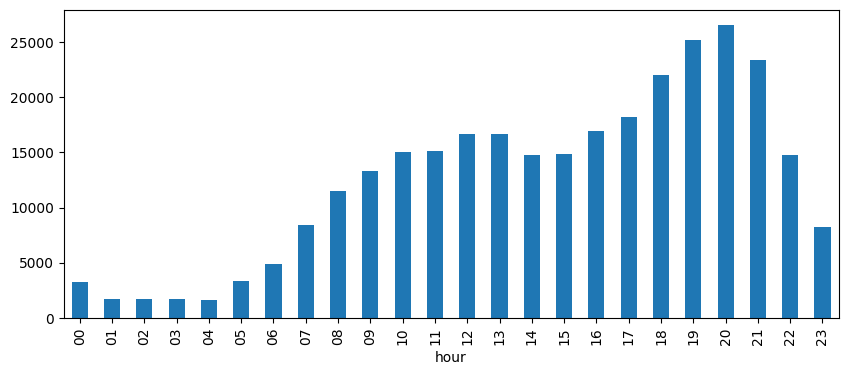

In [21]:
# Plot the number of requests in each hour of the day.
hours = spark.sql("""
    SELECT SUBSTRING(datee, 13, 2) AS hour, COUNT(*) AS requests
    FROM logs
    GROUP BY hour
    ORDER BY hour
""").toPandas()

hours.plot.bar(x="hour", y="requests", legend=False, figsize=(10, 4))

#### Task 4: Find the IP addresses that made requests to more than 35 distinct URLs

`COUNT(DISTINCT url)` counts the **different** pages each visitor requested, and `HAVING` keeps the visitors above 35. A person looks at a few pages; a visitor that requests hundreds of different pages is usually a **crawler** (a search-engine robot) or a scraper.

**Expected:** 12 addresses, all starting with `66.249.`, each with about 180 different URLs.

In [22]:
# Task 4: find the IP addresses that requested more than 35 distinct URLs.
spark.sql("""
    SELECT ip, COUNT(DISTINCT url) AS distinct_url_count
    FROM logs
    GROUP BY ip
    HAVING distinct_url_count > 35
    ORDER BY distinct_url_count DESC
""").show()

+-------------+------------------+
|           ip|distinct_url_count|
+-------------+------------------+
|66.249.75.211|               189|
|66.249.79.133|               188|
| 66.249.68.52|               188|
|66.249.92.242|               184|
|66.249.64.123|               183|
|66.249.86.148|               183|
|66.249.76.149|               183|
|66.249.80.102|               182|
|  66.249.65.9|               181|
| 66.249.75.82|               181|
|66.249.80.233|               180|
|66.249.78.154|               179|
+-------------+------------------+



Who are they? Look at the user agent these addresses send. `LIKE '66.249.%'` keeps the IP addresses that start with `66.249.`.

**Expected:** a single user agent, `Googlebot`: Google's crawler, indexing the shop's product pages for its search engine.

In [23]:
# Show the user agent of those IP addresses.
spark.sql("""
    SELECT user_agent, COUNT(*) AS requests
    FROM logs_parquet
    WHERE ip LIKE '66.249.%'
    GROUP BY user_agent
""").show(truncate=False)

+------------------------------------------------------------------------+--------+
|user_agent                                                              |requests|
+------------------------------------------------------------------------+--------+
|Mozilla/5.0 (compatible; Googlebot/2.1; +http://www.google.com/bot.html)|5983    |
+------------------------------------------------------------------------+--------+



## 5. More: the same parsing with a Spark DataFrame

**Goal:** See the Spark way of doing Step 3 without Hive. `spark.read.text` loads every line of the HDFS folder as one column, `value`, and `regexp_extract(column, pattern, n)` takes the **n**-th bracketed group of a regular expression, so one pattern gives one column per group. Here the pattern is passed to Spark directly rather than through SQL, so each backslash is written only once. `\S` means any character except a space.

**Expected:** the same columns as the Hive table.

In [24]:
# Parse the raw log lines from HDFS into columns with regexp_extract.
from pyspark.sql import functions as F

pattern = r'^(\S+) - - \[([^\]]+)\] "(\S+) (\S+) (\S+)" (\d+) (\d+) "([^"]*)" "([^"]*)"$'

raw = spark.read.text("hdfs://127.0.0.1:9000/user/hive/warehouse/access_log")

parsed = raw.select(
    F.regexp_extract("value", pattern, 1).alias("ip"),
    F.regexp_extract("value", pattern, 2).alias("datee"),
    F.regexp_extract("value", pattern, 3).alias("method"),
    F.regexp_extract("value", pattern, 4).alias("url"),
    F.regexp_extract("value", pattern, 5).alias("http_version"),
    F.regexp_extract("value", pattern, 6).alias("code1"),
    F.regexp_extract("value", pattern, 7).alias("code2"),
    F.regexp_extract("value", pattern, 8).alias("dash"),
    F.regexp_extract("value", pattern, 9).alias("user_agent")
)

parsed.show(3, truncate=40)

+-------------+--------------------------+------+------------------------------+------------+-----+-----+----+----------------------------------------+
|           ip|                     datee|method|                           url|http_version|code1|code2|dash|                              user_agent|
+-------------+--------------------------+------+------------------------------+------------+-----+-----+----+----------------------------------------+
| 87.73.228.43|26/Mar/2015:20:04:07 -0400|   GET|/product/under-armour-jacket-9|    HTTP/1.1|  200| 5766|   -|Mozilla/5.0 (Windows NT 6.1; WOW64; r...|
|219.249.37.73|28/Mar/2015:10:50:20 -0400|   GET|        /product/adidas-ball-4|    HTTP/1.1|  200| 7605|   -|Mozilla/5.0 (compatible; MSIE 10.0; W...|
|91.167.38.241|27/Mar/2015:20:59:35 -0400|   GET|                         /home|    HTTP/1.1|  200| 7431|   -|Mozilla/5.0 (iPhone; CPU iPhone OS 7_...|
+-------------+--------------------------+------+------------------------------+--------

Use the parsed DataFrame like any other: the pages that most often answered **404 Not Found** (a broken link or a mistyped address), and the same total checked with SQL on the Hive table.

**Expected:** the two totals are equal.

In [25]:
# The 5 URLs with the most "404 Not Found" errors, from the parsed DataFrame.
parsed.filter(F.col("code1") == "404").groupBy("url").count().orderBy(F.desc("count")).show(5, truncate=False)

+-----------------------+-----+
|url                    |count|
+-----------------------+-----+
|/home                  |1001 |
|/login                 |208  |
|/search                |159  |
|/checkout              |129  |
|/product/nike-air-max-9|116  |
+-----------------------+-----+
only showing top 5 rows


In [26]:
# Compare the number of 404 errors in the DataFrame and in the Hive table.
print("DataFrame:", parsed.filter(F.col("code1") == "404").count())
print("Hive table:", spark.sql("SELECT COUNT(*) FROM logs WHERE code1 = '404'").first()[0])

DataFrame: 11944
Hive table: 11944


## 6. Stop Spark and HDFS

In [27]:
# Stop the SparkSession and the HDFS daemons.
spark.stop()
!hdfs --daemon stop datanode
!hdfs --daemon stop namenode
print("Spark and HDFS stopped ✓")

Spark and HDFS stopped ✓


## Check your understanding

1. Why is a web server log called **unstructured** (or semi-structured) data, while `CompleteDataset.csv` is structured?
2. What does a **SerDe** do, and when does the RegexSerDe apply the regular expression: when the table is created, or when it is queried?
3. Why does the lab copy the data from `intermediate_logs` into a second table, instead of querying `intermediate_logs` directly?
4. Why did Task 2 show cut-off user agents on the `logs` table but not on `logs_parquet`?
5. What is the difference between an **external** and a **managed** table? What happens to the files in `/user/hive/warehouse/access_log` if you drop `intermediate_logs`?
6. Why does Impala need `invalidate metadata` after a table is created in Hive?
7. Task 4 found visitors with about 180 different URLs. Who are they, and why might a website want to know?